# Routing methods

**Question:** For the same fixed circuit and initial layout, does Lookahead routing use fewer gates or produce better noisy samples than SABRE?

I keep the SNP order, angles, backend, physical layout, optimization level and seeds fixed. Only the routing method changes. An earlier line-specific commuting-block router is mentioned in the pilot notes, but its notebook is not part of this folder. The retained commuting RZZ-order test is in [the commuting schedule notebook](hardware_commuting_schedule.ipynb).

## 1. Load the fixed problem

The [setup notebook](hardware_setup.ipynb) provides the circuit and scores.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware_experiments/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('docs/hardware_experiments/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Compile both routing methods

Routing makes two-qubit gates fit the device connections, adding SWAPs when needed. **SABRE** scores possible SWAPs using a heuristic; **Lookahead** searches a small tree of possible SWAP sequences. Both consider upcoming gates.

For each seed, I compile the same measured circuit using SABRE and Lookahead. The initial physical positions are fixed for both.

In [ ]:
circuit = make_circuit()
physical = list(range(n))
routers = {'SABRE': 'sabre', 'Lookahead': 'lookahead'}
compiled = {}
rows = []
for name, router in routers.items():
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend, optimization_level=2, initial_layout=physical,
            routing_method=router, seed_transpiler=seed,
        )
        compiled[name, seed] = manager.run(circuit)
        rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
resource_table = pd.DataFrame(rows)
display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
        .agg(['median', 'min', 'max']))

2q gates         2q depth          depth        
            median min max   median min max median min max
method                                                    
SABRE         28.0  26  28     23.0  21  23   57.0  57  57
Lookahead     28.0  28  28     23.0  23  23   57.0  57  57

## 3. Compare the resources

The box shows the middle half of the values, the line is the median, and the triangle is the mean.

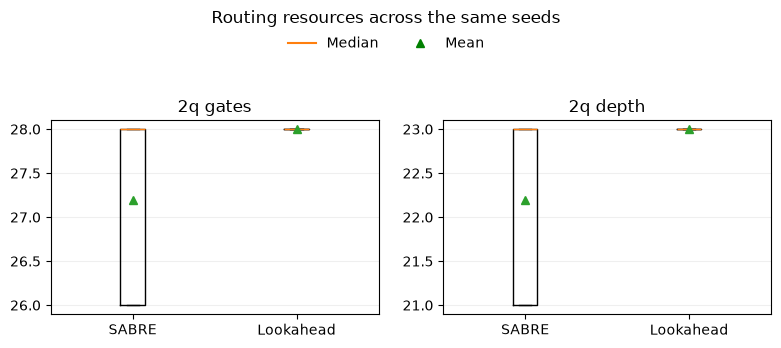

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, metric in zip(axes, ['2q gates', '2q depth']):
    data = [resource_table.loc[resource_table.method == name, metric] for name in routers]
    ax.boxplot(data, tick_labels=routers.keys(), showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Routing resources across the same seeds')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 4. Compare noisy samples

I simulate three compiled seeds and three repeats per seed for each method. These results are descriptive for this snapshot; a lower depth or gate count alone does not prove better noisy quality.

In [4]:
run_noise = True
if run_noise:
    if backend.num_qubits > 16:
        raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    samples = []
    for name in routers:
        for seed in noise_seeds:
            for repeat in range(noise_repeats):
                counts = simulator.run(
                    compiled[name, seed], shots=shots,
                    seed_simulator=9000 + seed * 100 + repeat,
                ).result().get_counts()
                samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
    noisy_results = pd.DataFrame(samples)
    display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
            .agg(['mean', 'std']))

mean cost           optimum frequency          
               mean       std              mean       std
method                                                   
SABRE      9.541992  0.211669          0.279514  0.011511
Lookahead  9.575738  0.184353          0.278971  0.011495

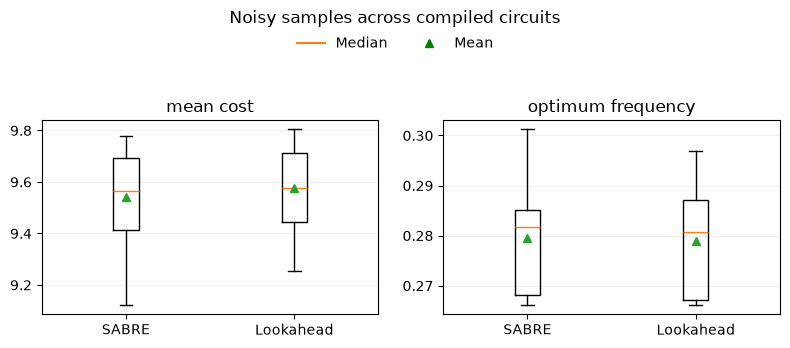

In [5]:
if run_noise:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        values = [noisy_results.loc[noisy_results.method == name, metric] for name in routers]
        ax.boxplot(values, tick_labels=routers.keys(), showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy samples across compiled circuits')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

## What did I find?

In the saved run, SABRE and Lookahead both had a median of 28 two-qubit gates and a two-qubit depth of 23. Their noisy mean costs and optimum frequencies were also close, so this test does not show a clear advantage for Lookahead.

The noisy comparison covers only three compiled seeds. A different graph or backend may give a different result.